# Tema 13 · Modelos de Clasificación — Guía 2: Naive Bayes y Máquinas de Vectores de Soporte (SVM) en Bolsa
**Curso:** Minería de Datos en Python (DM) · FISI · UNMSM · 2026-II · **Laboratorio 12 · Guía 2** · Docente: Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Objetivo:** entender el **teorema de Bayes** y el supuesto «ingenuo» de independencia, y el **margen**, el **núcleo (kernel)**, **C** y **gamma** de la SVM. Se contrasta *Mundo 2* (sintético: donde funcionan y donde fallan) con *Mundo 3* (régimen de volatilidad de SPY) y *Mundo 1* (dirección a 5 sesiones).

**Datos:** Yahoo Finance (28 activos, hasta el 19-nov-2026) con respaldo en CSV. **Nada de este material es asesoría de inversión.**

# 1. Importación de librerías y carga de datos

In [1]:
# Librerías del laboratorio
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")
SEMILLA = 2026  # semilla global: reproducibilidad
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"}
)

In [2]:
# Librerías de esta guía
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import (
    GridSearchCV,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.datasets import make_moons, make_classification
from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss

In [3]:
# Precios ajustados de 28 activos hasta el cierre del 19-nov-2026. Si los 4 CSV del curso (carpeta D03) están junto al notebook se usan
# (las cifras coinciden con las de la guía); si no, se descargan de Yahoo Finance (pueden variar en centésimas si Yahoo revisó precios)
import os

TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = {
    "cierres": "26.11.20.cierres_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "altos": "26.11.20.altos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "bajos": "26.11.20.bajos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "volumenes": "26.11.20.volumenes_28_activos_2010-01-04_2026-11-19.csv",
}
if all(os.path.exists(f) for f in ARCH.values()):
    cierres, altos, bajos, volumenes = [
        pd.read_csv(ARCH[k], index_col=0, parse_dates=True)
        for k in ["cierres", "altos", "bajos", "volumenes"]
    ]
    print("Se usó la foto de datos del curso (CSV)")
else:
    try:
        d = yf.download(
            TICKERS,
            start="2010-01-01",
            end="2026-11-20",
            auto_adjust=True,
            progress=False,
        )
        cierres, altos, bajos, volumenes = [
            d[c].reindex(columns=TICKERS) for c in ["Close", "High", "Low", "Volume"]
        ]
        print("Se descargó de Yahoo Finance")
    except Exception as e:
        raise SystemExit(
            "Falló la descarga de Yahoo Finance (%s): suba los 4 CSV del curso junto "
            "al notebook"
            % e
        )
for t in (cierres, altos, bajos, volumenes):
    t.index = pd.to_datetime(t.index)
print(
    "Dimensiones:",
    cierres.shape,
    "| desde",
    cierres.index.min().date(),
    "hasta",
    cierres.index.max().date(),
)
print(
    "Último cierre de SPY:",
    round(float(cierres["SPY"].dropna().iloc[-1]), 2),
    "| VIX:",
    round(float(cierres["^VIX"].dropna().iloc[-1]), 2),
)

Se usó la foto de datos del curso (CSV)
Dimensiones: (4249, 28) | desde 2010-01-04 hasta 2026-11-19
Último cierre de SPY: 715.87 | VIX: 28.44


# 2. Parte I — El teorema de Bayes con números de bolsa
Supongamos que en el 10 % de las ventanas de 10 sesiones hay una caída de 4 % o más (P(C) = 0,10). Un «aviso de VIX alto» aparece en el 70 % de las ventanas con caída y en el 20 % de las ventanas sin caída. ¿Cuál es la probabilidad de caída cuando suena el aviso?

In [4]:
# Teorema de Bayes: P(C | aviso) = P(aviso | C) · P(C) / P(aviso)
p_c, p_av_c, p_av_nc = 0.10, 0.70, 0.20
p_aviso = p_av_c * p_c + p_av_nc * (1 - p_c)
posterior = p_av_c * p_c / p_aviso
print(
    "P(aviso) =",
    round(p_aviso, 3),
    "| P(caída | aviso) =",
    round(posterior, 3),
    "| razón frente a la tasa base:",
    round(posterior / p_c, 2),
)
# Dos avisos independientes (supuesto «ingenuo»): se multiplican las verosimilitudes
post2 = p_av_c**2 * p_c / (p_av_c**2 * p_c + p_av_nc**2 * (1 - p_c))
print("Con dos avisos independientes: P(caída | ambos) =", round(post2, 3))

P(aviso) = 0.25 | P(caída | aviso) = 0.28 | razón frente a la tasa base: 2.8
Con dos avisos independientes: P(caída | ambos) = 0.576


# 3. Parte II — Laboratorio de contraste sintético (Mundo 2)
**Fenómeno F2.** Naive Bayes supone que las variables son independientes dado el evento. Si copiamos la misma variable varias veces, NB **cuenta la misma evidencia varias veces** y se vuelve sobreconfiado: el AUC casi no cambia, pero la **log-loss y el Brier** empeoran. La regresión logística, que reparte pesos, no se contagia.

 copias      modelo   AUC  log_loss  Brier  prob_extremas
      0 Naive Bayes 0.787     0.498  0.164          0.011
      0   Logística 0.787     0.499  0.165          0.010
      1 Naive Bayes 0.776     0.531  0.174          0.075
      1   Logística 0.787     0.499  0.165          0.011
      3 Naive Bayes 0.756     0.716  0.209          0.299
      3   Logística 0.787     0.499  0.165          0.012
      6 Naive Bayes 0.742     1.100  0.248          0.502
      6   Logística 0.785     0.501  0.165          0.014
     10 Naive Bayes 0.732     1.688  0.278          0.659
     10   Logística 0.787     0.499  0.165          0.013


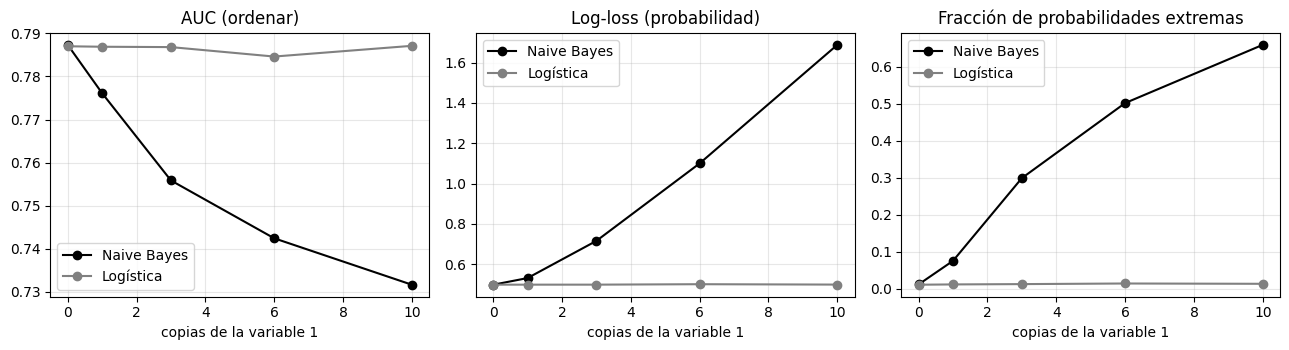

In [5]:
# Dos variables informativas independientes + copias ruidosas de la primera
n = 6000
y_s = rng.binomial(1, 0.3, n)
x1 = rng.normal(0.8 * y_s, 1.0)
x2 = rng.normal(0.8 * y_s, 1.0)
filas = []
for copias in [0, 1, 3, 6, 10]:
    extra = (
        np.column_stack([x1 + rng.normal(0, 0.3, n) for _ in range(copias)])
        if copias
        else np.empty((n, 0))
    )
    Xd = np.column_stack([x1, x2, extra])
    Xe, Xp, ye, yp = train_test_split(
        Xd, y_s, test_size=0.4, random_state=SEMILLA, stratify=y_s
    )
    for nombre, m in [
        ("Naive Bayes", GaussianNB()),
        ("Logística", LogisticRegression(max_iter=2000)),
    ]:
        p = m.fit(Xe, ye).predict_proba(Xp)[:, 1]
        filas.append(
            [
                copias,
                nombre,
                roc_auc_score(yp, p),
                log_loss(yp, np.clip(p, 1e-6, 1 - 1e-6)),
                brier_score_loss(yp, p),
                np.mean((p < 0.02) | (p > 0.98)),
            ]
        )
dup = pd.DataFrame(
    filas, columns=["copias", "modelo", "AUC", "log_loss", "Brier", "prob_extremas"]
)
print(dup.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for m_, c in [("Naive Bayes", "black"), ("Logística", "gray")]:
    s = dup[dup["modelo"] == m_]
    ax[0].plot(s["copias"], s["AUC"], "o-", color=c, label=m_)
    ax[1].plot(s["copias"], s["log_loss"], "o-", color=c, label=m_)
    ax[2].plot(s["copias"], s["prob_extremas"], "o-", color=c, label=m_)
for a, t in zip(
    ax,
    ["AUC (ordenar)", "Log-loss (probabilidad)", "Fracción de probabilidades extremas"],
):
    a.set_title(t)
    a.set_xlabel("copias de la variable 1")
    a.legend()
plt.tight_layout()
plt.show()

**Fenómeno F3.** La SVM busca el **hiperplano de máximo margen**; con un **kernel RBF** dibuja fronteras curvas. Dos controles: **C** (penalización de errores: alto = frontera rígida que se ajusta al ruido) y **gamma** (alcance de cada punto: alto = frontera sinuosa). Sin **escalar** las variables, la de mayor magnitud domina las distancias.

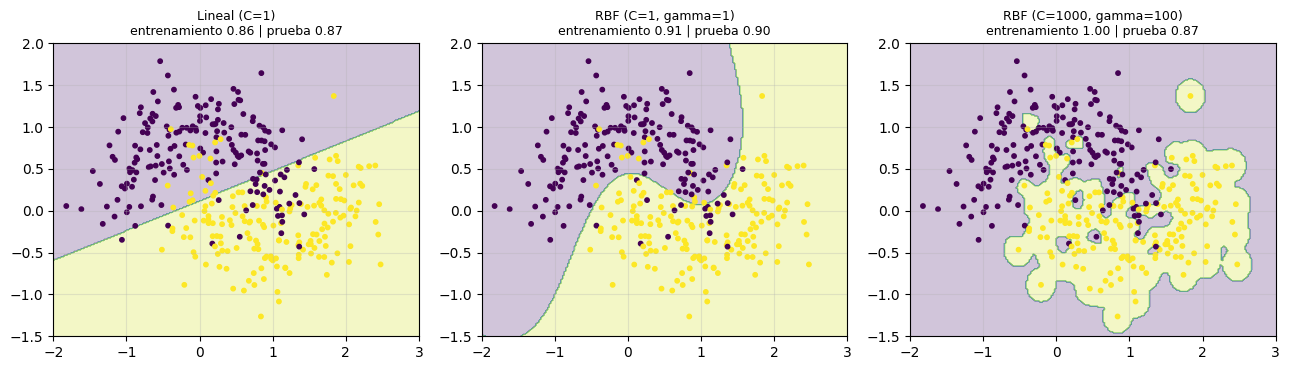

In [6]:
# Lunas (frontera curva): SVM lineal, RBF razonable y RBF con gamma excesivo
Xm, ym = make_moons(n_samples=600, noise=0.30, random_state=SEMILLA)
Xm_e, Xm_p, ym_e, ym_p = train_test_split(
    Xm, ym, test_size=0.4, random_state=SEMILLA, stratify=ym
)
modelos = {
    "Lineal (C=1)": SVC(kernel="linear", C=1),
    "RBF (C=1, gamma=1)": SVC(kernel="rbf", C=1, gamma=1),
    "RBF (C=1000, gamma=100)": SVC(kernel="rbf", C=1000, gamma=100),
}
xx, yy = np.meshgrid(np.linspace(-2, 3, 220), np.linspace(-1.5, 2, 220))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (nombre, m) in zip(ax, modelos.items()):
    m.fit(Xm_e, ym_e)
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, zz, alpha=0.25, cmap="viridis")
    a.scatter(Xm_e[:, 0], Xm_e[:, 1], c=ym_e, s=10, cmap="viridis")
    a.set_title(
        f"{nombre}\nentrenamiento {m.score(Xm_e, ym_e):.2f} | prueba "
        f"{m.score(Xm_p, ym_p):.2f}",
        fontsize=9,
    )
plt.tight_layout()
plt.show()

In [7]:
# Escala: una variable en miles frente a otra en unidades (la información está en la segunda)
Xe_ = np.column_stack([rng.normal(0, 1000, 800), rng.normal(0, 1, 800)])
ye_ = (Xe_[:, 1] > 0).astype(int)
sin_escalar = cross_val_score(SVC(kernel="rbf"), Xe_, ye_, cv=5).mean()
con_escala = cross_val_score(
    make_pipeline(StandardScaler(), SVC(kernel="rbf")), Xe_, ye_, cv=5
).mean()
print(
    "Exactitud con validación cruzada, SVM RBF sin escalar:",
    round(sin_escalar, 3),
    "| escalando en un Pipeline:",
    round(con_escala, 3),
)

Exactitud con validación cruzada, SVM RBF sin escalar: 0.535 | escalando en un Pipeline: 0.991


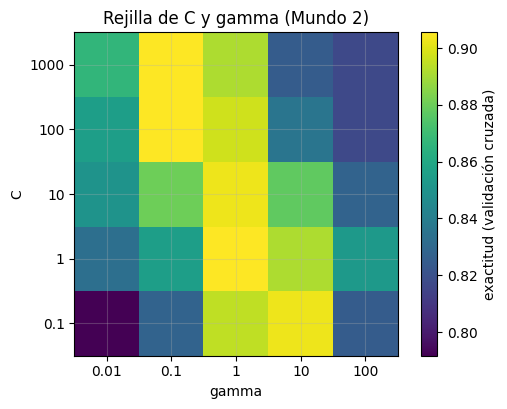

Mejores parámetros: {'C': 1, 'gamma': 1} | exactitud de validación: 0.906 | exactitud en la prueba: 0.904


In [8]:
# Búsqueda en rejilla de C y gamma (validación cruzada) y mapa de calor
Cs, gammas = [0.1, 1, 10, 100, 1000], [0.01, 0.1, 1, 10, 100]
bus = GridSearchCV(
    SVC(kernel="rbf"), {"C": Cs, "gamma": gammas}, cv=5, scoring="accuracy"
).fit(Xm_e, ym_e)
res = bus.cv_results_["mean_test_score"].reshape(len(Cs), len(gammas))
plt.figure(figsize=(6, 4.2))
plt.imshow(res, cmap="viridis", origin="lower")
plt.colorbar(label="exactitud (validación cruzada)")
plt.xticks(range(len(gammas)), gammas)
plt.yticks(range(len(Cs)), Cs)
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Rejilla de C y gamma (Mundo 2)")
plt.show()
print(
    "Mejores parámetros:",
    bus.best_params_,
    "| exactitud de validación:",
    round(bus.best_score_, 3),
    "| exactitud en la prueba:",
    round(bus.score(Xm_p, ym_p), 3),
)

# 4. Datos de SPY: variables causales y objetivos
La partición es cronológica (70 % / 30 %) con embargo de 22 filas; las variables usan solo información al cierre de *t*.

In [9]:
# Variables causales de un activo: solo información conocida al cierre del día t
TICKER = "SPY"
cierre = cierres[TICKER].dropna()
alto, bajo, volumen = (
    altos[TICKER].reindex(cierre.index),
    bajos[TICKER].reindex(cierre.index),
    volumenes[TICKER].reindex(cierre.index),
)
vix = cierres["^VIX"].reindex(cierre.index).ffill()
r = np.log(cierre).diff() * 100  # retorno logarítmico diario en %
X = pd.DataFrame(
    {
        "ret_1": r,
        "ret_5": r.rolling(5).sum(),
        "ret_22": r.rolling(22).sum(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(5),
        "parkinson": (np.log(alto / bajo) / np.sqrt(4 * np.log(2)) * 100)
        .rolling(5)
        .mean(),
        "dist_sma50": (cierre / cierre.rolling(50).mean() - 1) * 100,
        "rango_22": (cierre - bajo.rolling(22).min())
        / (alto.rolling(22).max() - bajo.rolling(22).min()),
        "d_volumen": np.log(volumen / volumen.rolling(22).mean()),
    }
).loc["2012-01-01":]
VARS = list(X.columns)
print(TICKER, "| variables:", VARS)

SPY | variables: ['ret_1', 'ret_5', 'ret_22', 'vol_5', 'vol_22', 'vol_66', 'vix', 'd_vix', 'parkinson', 'dist_sma50', 'rango_22', 'd_volumen']


In [10]:
# Tres objetivos binarios del mismo activo (todos miran al FUTURO; las variables solo al pasado)
y_dir5 = (cierre.shift(-5) / cierre > 1).astype(
    float
)  # ¿cierra más alto dentro de 5 sesiones?
vol_fut = r.shift(-22).rolling(22).std()  # volatilidad de las próximas 22 sesiones
caida = pd.concat([cierre.shift(-k) / cierre - 1 for k in range(1, 11)], axis=1).min(
    axis=1
)  # peor caída en las próximas 10 sesiones
datos = (
    X.join(y_dir5.rename("dir5"))
    .join(vol_fut.rename("vol_fut"))
    .join(caida.rename("caida"))
    .dropna()
)
corte = int(len(datos) * 0.7)
H = 22  # embargo = horizonte más largo
ent, pru = datos.iloc[: corte - H], datos.iloc[corte:]
umbral_vol = ent["vol_fut"].quantile(0.70)  # el umbral sale SOLO del entrenamiento
for t in (ent, pru):
    t["alta_vol"] = (t["vol_fut"] > umbral_vol).astype(int)
    t["crash"] = (t["caida"] <= -0.04).astype(int)
    t["dir5"] = t["dir5"].astype(int)
print(
    "Entrenamiento:",
    len(ent),
    "filas, hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "filas, desde",
    pru.index.min().date(),
)
for obj in ["dir5", "alta_vol", "crash"]:
    print(
        f"{obj:9s} tasa base entrenamiento {ent[obj].mean():.3f} | prueba "
        f"{pru[obj].mean():.3f}"
    )

Entrenamiento: 2582 filas, hasta 2022-04-05 | Prueba: 1117 filas, desde 2022-05-09
dir5      tasa base entrenamiento 0.624 | prueba 0.601
alta_vol  tasa base entrenamiento 0.300 | prueba 0.353
crash     tasa base entrenamiento 0.088 | prueba 0.103


# 5. Parte III — Régimen de alta volatilidad de SPY (Mundo 3) con NB y SVM
La búsqueda de **C** y **gamma** usa `TimeSeriesSplit` con `gap = 22` **solo dentro del entrenamiento**; la prueba se mira una vez.

In [11]:
# Modelos: logística (referencia), Naive Bayes, SVM lineal y SVM RBF con búsqueda cronológica
tscv = TimeSeriesSplit(n_splits=4, gap=H)
rej = {"svc__C": [0.1, 1, 10], "svc__gamma": [0.01, 0.03, 0.1]}
svm_rbf = GridSearchCV(
    make_pipeline(
        StandardScaler(), SVC(kernel="rbf", probability=True, random_state=SEMILLA)
    ),
    rej,
    cv=tscv,
    scoring="roc_auc",
).fit(ent[VARS], ent["alta_vol"])
print(
    "SVM RBF, mejores parámetros:",
    svm_rbf.best_params_,
    "| AUC de validación:",
    round(svm_rbf.best_score_, 3),
)
modelos = {
    "Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Naive Bayes": GaussianNB(),
    "SVM lineal": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=0.1, probability=True, random_state=SEMILLA),
    ),
    "SVM RBF": svm_rbf.best_estimator_,
}
filas, probs = [], {}
for nombre, m in modelos.items():
    m.fit(ent[VARS], ent["alta_vol"])
    p = m.predict_proba(pru[VARS])[:, 1]
    probs[nombre] = p
    y_hat = (p >= 0.5).astype(int)
    filas.append(
        [
            nombre,
            roc_auc_score(pru["alta_vol"], p),
            average_precision_score(pru["alta_vol"], p),
            f1_score(pru["alta_vol"], y_hat),
            brier_score_loss(pru["alta_vol"], p),
            balanced_accuracy_score(pru["alta_vol"], y_hat),
        ]
    )
tabla_vol = pd.DataFrame(
    filas,
    columns=["modelo", "AUC-ROC", "AUC-PR", "F1", "Brier", "exactitud balanceada"],
).sort_values("AUC-ROC", ascending=False)
print("Tasa base de «alta volatilidad» en la prueba:", round(pru["alta_vol"].mean(), 3))
print(tabla_vol.round(3).to_string(index=False))

SVM RBF, mejores parámetros: {'svc__C': 0.1, 'svc__gamma': 0.03} | AUC de validación: 0.73


Tasa base de «alta volatilidad» en la prueba: 0.353
     modelo  AUC-ROC  AUC-PR    F1  Brier  exactitud balanceada
    SVM RBF    0.839   0.792 0.651  0.147                 0.738
  Logística    0.833   0.777 0.638  0.151                 0.729
 SVM lineal    0.825   0.779 0.641  0.151                 0.732
Naive Bayes    0.819   0.787 0.684  0.185                 0.757


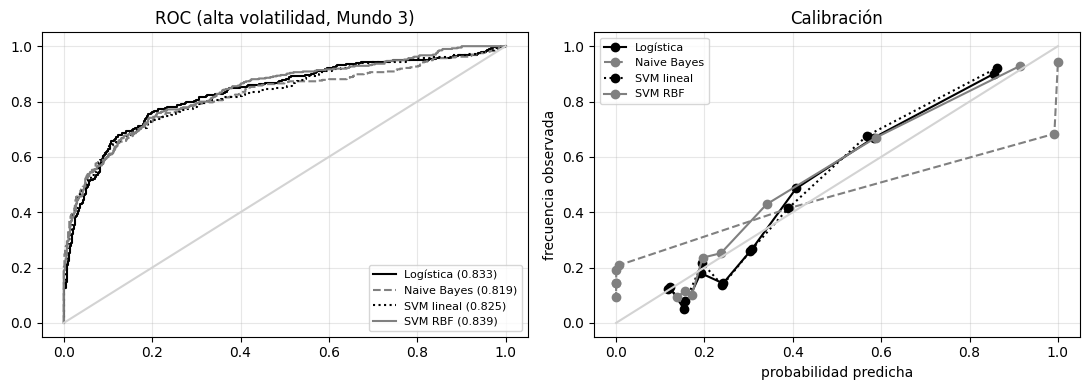

In [12]:
# Curvas ROC y de calibración de los cuatro modelos
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
estilos = {
    "Logística": ("black", "-"),
    "Naive Bayes": ("gray", "--"),
    "SVM lineal": ("black", ":"),
    "SVM RBF": ("gray", "-"),
}
for nombre, p in probs.items():
    c, ls = estilos[nombre]
    f, t, _ = roc_curve(pru["alta_vol"], p)
    ax[0].plot(
        f,
        t,
        color=c,
        ls=ls,
        label=f"{nombre} ({roc_auc_score(pru['alta_vol'], p):.3f})",
    )
    fr, mp = calibration_curve(pru["alta_vol"], p, n_bins=8, strategy="quantile")
    ax[1].plot(mp, fr, "o-", color=c, ls=ls, label=nombre)
ax[0].plot([0, 1], [0, 1], color="lightgray")
ax[0].set_title("ROC (alta volatilidad, Mundo 3)")
ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], color="lightgray")
ax[1].set_title("Calibración")
ax[1].set_xlabel("probabilidad predicha")
ax[1].set_ylabel("frecuencia observada")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 6. Parte IV — La dirección a 5 sesiones (Mundo 1): los mismos modelos, el mismo resultado de siempre

In [13]:
# Mismos cuatro modelos sobre la dirección a 5 sesiones
filas = []
for nombre, m in modelos.items():
    m.fit(ent[VARS], ent["dir5"])
    p = m.predict_proba(pru[VARS])[:, 1]
    filas.append(
        [
            nombre,
            roc_auc_score(pru["dir5"], p),
            accuracy_score(pru["dir5"], (p >= 0.5).astype(int)),
            balanced_accuracy_score(pru["dir5"], (p >= 0.5).astype(int)),
        ]
    )
print(
    "Tasa base de «sube» en la prueba:",
    round(pru["dir5"].mean(), 3),
    "(exactitud de «siempre sube»)",
)
print(
    pd.DataFrame(
        filas, columns=["modelo", "AUC-ROC", "exactitud", "exactitud balanceada"]
    )
    .round(3)
    .to_string(index=False)
)

Tasa base de «sube» en la prueba: 0.601 (exactitud de «siempre sube»)
     modelo  AUC-ROC  exactitud  exactitud balanceada
  Logística    0.497      0.602                 0.501
Naive Bayes    0.525      0.604                 0.509
 SVM lineal    0.515      0.601                 0.500
    SVM RBF    0.504      0.600                 0.501


# 7. Resumen
- **Naive Bayes** es rápido y compite cuando las variables son casi independientes; con variables duplicadas se vuelve **sobreconfiado** (probabilidades extremas, log-loss alta) aunque ordene bien.
- **SVM:** escalar siempre; **C** y **gamma** se eligen con validación cronológica; con gamma muy alto sobreajusta.
- En bolsa: la volatilidad se anticipa (AUC alto con casi cualquier modelo); la dirección no (AUC ≈ 0,5 con todos).